In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import os
os.environ['AUTO_DIR'] = '<LOCAL_PATH_TO_AUTO-07P>'  # Required for bifurcation_finder (see docs/INSTALL_AUTO.md)

In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from tipbox.bifurcation.polynomial_model import generate_random_polynomial_model, simulate_to_equilibrium
from tipbox.bifurcation.bifurcation_finder import find_all_bifurcations


### Generate Trajectory

In [3]:
# Generate a random polynomial model until convergence is reached (max_attempts=100)
key = jax.random.PRNGKey(0)
model = generate_random_polynomial_model(key, max_attempts=100)

if model is not None:
    print(f"Converged with equilibrium at: {model.equi}")

W0000 00:00:1762353534.309877 17330427 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1762353534.349477 17330427 service.cc:145] XLA service 0x115050960 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762353534.349620 17330427 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1762353534.353474 17330427 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1762353534.353485 17330427 mps_client.cc:384] XLA backend will use up to 5726240768 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M1

systemMemory: 8.00 GB
maxCacheSize: 2.67 GB

Converged with equilibrium at: [-1.0533764 -0.810535 ]


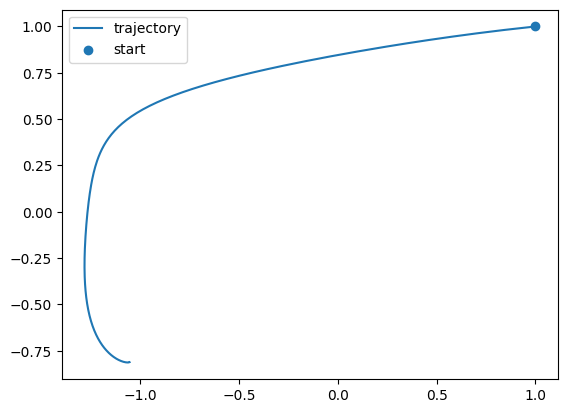

In [4]:
# Visually inspect the model trajectory
s0 = jnp.array([1.0, 1.0])

equi_pt, is_converged, traj = simulate_to_equilibrium(
    model.pars_a, model.pars_b, s0
)

# Plot the trajectory
plt.plot(traj[:, 0], traj[:, 1], label="trajectory")
plt.scatter(traj[0, 0], traj[0, 1], color='C0', label="start")
plt.legend()
plt.show();


### Find Bifurcation

In [5]:
bifurcations = find_all_bifurcations(
    model,
    param_range=(-5.0, 5.0)
)

Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a1         L2-NORM          x             y       
   1    43  LP    2   1.02742E-01   3.57972E-01  -1.16271E-01  -3.38563E-01
   1    49  LP    3  -7.90746E-03   7.30199E-02  -1.70545E-03   7.30000E-02
   1   115  UZ    4   5.00000E+00   1.47223E+00   1.21907E+00   8.25419E-01

 Total Time    0.795E-02
model ... done
Saving to b.outa1, s.outa1, and d.outa1 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a3         L2-NORM          x             y       
   1    54  UZ    2   5.00000E+00   1.84683E+00  -1.58291E+00  -9.51408E-01

 Total Time

In [6]:
bifurcations

[BifurcationPoint(bif_type='fold', bif_param_name='a1', bif_param_index=0, bif_value=0.10274155754),
 BifurcationPoint(bif_type='null', bif_param_name='a3', bif_param_index=2, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='a6', bif_param_index=5, bif_value=0.0),
 BifurcationPoint(bif_type='fold', bif_param_name='a7', bif_param_index=6, bif_value=0.20517743069),
 BifurcationPoint(bif_type='null', bif_param_name='a9', bif_param_index=8, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='a10', bif_param_index=9, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='b2', bif_param_index=11, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='b5', bif_param_index=14, bif_value=0.0),
 BifurcationPoint(bif_type='null', bif_param_name='b6', bif_param_index=15, bif_value=0.0),
 BifurcationPoint(bif_type='fold', bif_param_name='b10', bif_param_index=19, bif_value=0.55842387183)]

In [7]:
# Show bifurcations found
print(f"Found {len(bifurcations)} bifurcations:")
for i, bif in enumerate(bifurcations):
    print(f"  {i+1}. {bif.bif_type:15s} at {bif.bif_param_name} = {bif.bif_value:.3f}")

Found 10 bifurcations:
  1. fold            at a1 = 0.103
  2. null            at a3 = 0.000
  3. null            at a6 = 0.000
  4. fold            at a7 = 0.205
  5. null            at a9 = 0.000
  6. null            at a10 = 0.000
  7. null            at b2 = 0.000
  8. null            at b5 = 0.000
  9. null            at b6 = 0.000
  10. fold            at b10 = 0.558



### API Demonstration

In [ ]:
from tipbox.bifurcation.stochastic_simulator import simulate_training_trajectory

# Pick the first bifurcation (not null)
target_bif = None
for bif in bifurcations:
    if bif.bif_type != 'null':
        target_bif = bif
        break

if target_bif:
    print(f"Simulating trajectory to {target_bif.bif_type} bifurcation...")
    
    # Generate trajectory
    key, subkey = jax.random.split(key)
    result = simulate_training_trajectory(
        model, 
        target_bif, 
        subkey, 
        series_len=500
    )
    
    if result:
        time, trajectory, label = result
        print(f"Successfully generated {label} trajectory")
        print(f"Shape: {trajectory.shape}")
        print(f"Time range: [{time[0]:.1f}, {time[-1]:.1f}]")
    else:
        print("Failed to generate trajectory (transition too early)")
else:
    print("No bifurcations found!")


Simulating trajectory to fold bifurcation...
✅ Successfully generated fold trajectory
   Shape: (500, 2)
   Time range: [0.0, 499.0]


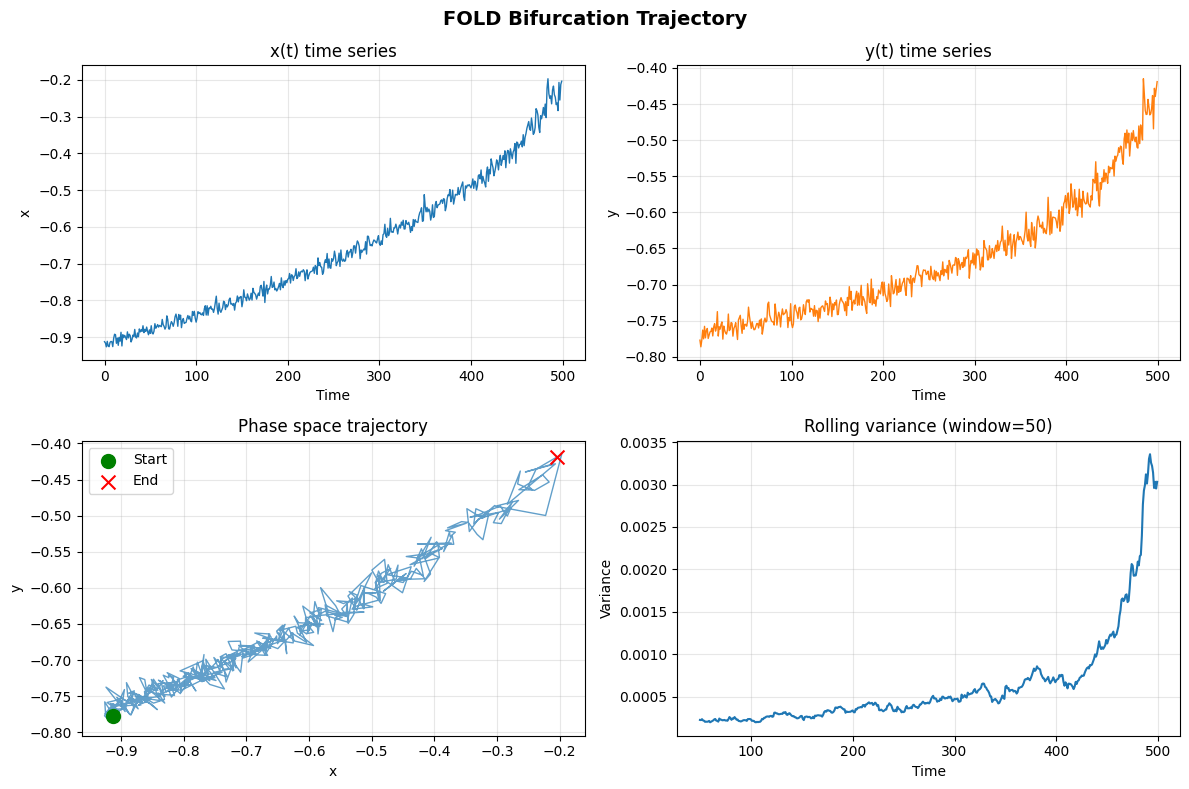

In [9]:
# Visualize the trajectory
if result:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    # Time series of x
    axes[0, 0].plot(time, trajectory[:, 0], linewidth=1)
    axes[0, 0].set_xlabel('Time')
    axes[0, 0].set_ylabel('x')
    axes[0, 0].set_title('x(t) time series')
    axes[0, 0].grid(True, alpha=0.3)
    
    # Time series of y
    axes[0, 1].plot(time, trajectory[:, 1], linewidth=1, color='C1')
    axes[0, 1].set_xlabel('Time')
    axes[0, 1].set_ylabel('y')
    axes[0, 1].set_title('y(t) time series')
    axes[0, 1].grid(True, alpha=0.3)
    
    # Phase space
    axes[1, 0].plot(trajectory[:, 0], trajectory[:, 1], linewidth=1, alpha=0.7)
    axes[1, 0].scatter(trajectory[0, 0], trajectory[0, 1], s=100, c='green', 
                       marker='o', label='Start', zorder=5)
    axes[1, 0].scatter(trajectory[-1, 0], trajectory[-1, 1], s=100, c='red', 
                       marker='x', label='End', zorder=5)
    axes[1, 0].set_xlabel('x')
    axes[1, 0].set_ylabel('y')
    axes[1, 0].set_title('Phase space trajectory')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Variance over time (early warning signal)
    window = 50
    rolling_var = [jnp.var(trajectory[max(0, i-window):i, 0]) 
                   for i in range(window, len(trajectory))]
    axes[1, 1].plot(time[window:], rolling_var, linewidth=1.5)
    axes[1, 1].set_xlabel('Time')
    axes[1, 1].set_ylabel('Variance')
    axes[1, 1].set_title(f'Rolling variance (window={window})')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.suptitle(f'{label.upper()} Bifurcation Trajectory', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [ ]:
from tipbox import generate

key = jax.random.PRNGKey(123)
time, traj, info = generate.generate(
    key,
    num_timesteps=500,
    bifurcation_type='transcritical',
    null_simulation=True,
)

if traj is not None:
    print(f"Generated {info['bifurcation_type']} trajectory")
    print(f"Model recovery rate: {info['recovery_rate']:.4f}")
    print(f"Bifurcation at {info['bifurcation'].bif_param_name} = {info['bifurcation'].bif_value:.3f}")
else:
    print("Could not find model with fold bifurcation")


Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a2         L2-NORM          x             y       
   1    47  UZ    2   5.00000E+00   2.71338E+00   2.30430E+00   1.43269E+00

 Total Time    0.461E-02
model ... done
Saving to b.outa2, s.outa2, and d.outa2 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a3         L2-NORM          x             y       
   1    58  UZ    2   5.00000E+00   2.56994E+00   2.16373E+00   1.38667E+00

 Total Time    0.289E-02
model ... done
Saving to b.outa3, s.outa3, and d.outa3 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configure

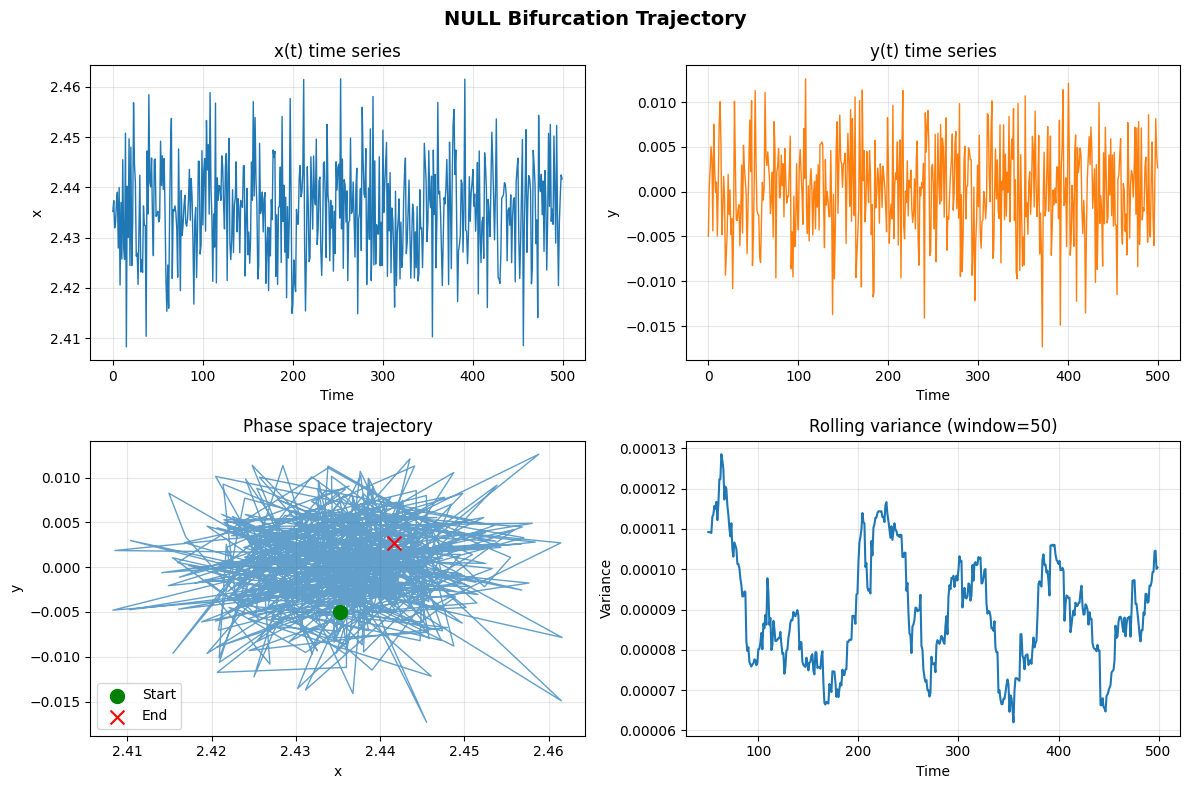

In [43]:
# Visualize the trajectory
if result:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    # Time series of x
    axes[0, 0].plot(time, traj[:, 0], linewidth=1)
    axes[0, 0].set_xlabel('Time')
    axes[0, 0].set_ylabel('x')
    axes[0, 0].set_title('x(t) time series')
    axes[0, 0].grid(True, alpha=0.3)
    
    # Time series of y
    axes[0, 1].plot(time, traj[:, 1], linewidth=1, color='C1')
    axes[0, 1].set_xlabel('Time')
    axes[0, 1].set_ylabel('y')
    axes[0, 1].set_title('y(t) time series')
    axes[0, 1].grid(True, alpha=0.3)
    
    # Phase space
    axes[1, 0].plot(traj[:, 0], traj[:, 1], linewidth=1, alpha=0.7)
    axes[1, 0].scatter(traj[0, 0], traj[0, 1], s=100, c='green', 
                       marker='o', label='Start', zorder=5)
    axes[1, 0].scatter(traj[-1, 0], traj[-1, 1], s=100, c='red', 
                       marker='x', label='End', zorder=5)
    axes[1, 0].set_xlabel('x')
    axes[1, 0].set_ylabel('y')
    axes[1, 0].set_title('Phase space trajectory')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Variance over time (early warning signal)
    window = 50
    rolling_var = [jnp.var(traj[max(0, i-window):i, 0]) 
                   for i in range(window, len(traj))]
    axes[1, 1].plot(time[window:], rolling_var, linewidth=1.5)
    axes[1, 1].set_xlabel('Time')
    axes[1, 1].set_ylabel('Variance')
    axes[1, 1].set_title(f'Rolling variance (window={window})')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.suptitle(f'{info["bifurcation_type"].upper()} Bifurcation Trajectory', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


In [ ]:
# Generate a balanced dataset of different bifurcation types
import numpy as np
from tqdm.auto import tqdm

key = jax.random.PRNGKey(42)
n_per_type = 10  # Generate 10 of each type

trajectories = []
labels = []
bif_types = []

print("Generating training dataset...")
print("=" * 60)

# Generate fold trajectories
print("\n🔹 Generating FOLD bifurcations...")
for i in tqdm(range(n_per_type), desc="Fold"):
    key, subkey = jax.random.split(key)
    result = generate.generate_pnas_style(subkey, bifurcation_type='fold', max_model_attempts=100)
    
    if result[1] is not None:
        time, traj, info = result
        trajectories.append(traj[:, 0])  # Just x variable
        labels.append(0)  # fold = 0
        bif_types.append('fold')

# Generate hopf trajectories  
print("\n🔹 Generating HOPF bifurcations...")
for i in tqdm(range(n_per_type), desc="Hopf"):
    key, subkey = jax.random.split(key)
    result = generate.generate_pnas_style(subkey, bifurcation_type='hopf', max_model_attempts=100)
    
    if result[1] is not None:
        time, traj, info = result
        trajectories.append(traj[:, 0])
        labels.append(1)  # hopf = 1
        bif_types.append('hopf')

# Generate null trajectories
print("\n🔹 Generating NULL trajectories...")
for i in tqdm(range(n_per_type), desc="Null"):
    key, subkey = jax.random.split(key)
    result = generate.generate_pnas_style(subkey, bifurcation_type='null', max_model_attempts=100)
    
    if result[1] is not None:
        time, traj, info = result
        trajectories.append(traj[:, 0])
        labels.append(2)  # null = 2
        bif_types.append('null')

print("\n" + "=" * 60)
print(f"Generated {len(trajectories)} trajectories")
print(f"Fold: {labels.count(0)}")
print(f"Hopf: {labels.count(1)}")
print(f"Null: {labels.count(2)}")


In [ ]:
# Visualize sample trajectories from each class
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

label_names = ['Fold', 'Hopf', 'Null']
colors = ['C0', 'C1', 'C2']

for label_idx, (ax, name, color) in enumerate(zip(axes, label_names, colors)):
    # Find first 3 trajectories of this type
    indices = [i for i, l in enumerate(labels) if l == label_idx][:3]
    
    for i in indices:
        ax.plot(trajectories[i], alpha=0.6, linewidth=1.5, color=color)
    
    ax.set_xlabel('Time')
    ax.set_ylabel('x')
    ax.set_title(f'{name} Trajectories', fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
